<a href="https://colab.research.google.com/github/cbvxil/international-airpassengers-project/blob/main/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone project - Air passengers, start to finish

The course pipeline, on this series: explore it, decompose it, set the
benchmark floor, check what the floor leaves on the table, fit a model
through the framework, cross-validate, and read the result against the
floor.

**What is graded is the process, not the number.** A low MASE from one
holdout with no intervals scores worse than an honest analysis that
concludes the benchmark wins.

Full rules and report requirements: `brief.md`. Grading: `rubric.md`. This
notebook is the first deliverable; it should run top to bottom in under ten
minutes on Colab.

This notebook is a starter. You may swap in your own series or your own
framework - see "Your own data or method" in `brief.md`.

In [2]:
import sys

if "google.colab" in sys.modules:
    !git clone -q https://github.com/SDAIAAcademy/international-airpassengers-project.git /content/proj
    %cd /content/proj
    !pip install -q -e .

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from coursekit import plotting as P
from coursekit import scoring

P.use_course_style()

SEASON_LENGTH = 12
H = 12            # forecast horizon for cross-validation
H_REPORT = 24     # forecast horizon for the report

fatal: destination path '/content/proj' already exists and is not an empty directory.
/content/proj
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for international-airpassengers-project (pyproject.toml) ... done


---
# 0. The data

Monthly international air passenger numbers, 1949-01 to 1960-12: 144
observations, no gaps. The Box & Jenkins classic (1970) — twelve years of
growth, and a year that does not repeat the same way twice.

Fetched from statsmodels' R-datasets on first run; no download step.

In [3]:
from statsmodels.datasets import get_rdataset

raw = get_rdataset("AirPassengers").data
t = raw["time"].astype(float).to_numpy()
years = np.floor(t).astype(int)
months = np.clip(np.round((t - years) * 12).astype(int) + 1, 1, 12)
df = pd.DataFrame({
    "unique_id": "Air passengers (Box & Jenkins)",
    "ds": pd.to_datetime(pd.Series(years).astype(str) + "-" +
                         pd.Series(months).astype(str).str.zfill(2) + "-01"),
    "y": raw["value"].astype(float),
}).sort_values("ds").reset_index(drop=True)
df.head()

,unique_id,ds,y
0,Air passengers (Box & Jenkins),1949-01-01,112.0
1,Air passengers (Box & Jenkins),1949-02-01,118.0
2,Air passengers (Box & Jenkins),1949-03-01,132.0
3,Air passengers (Box & Jenkins),1949-04-01,129.0
4,Air passengers (Box & Jenkins),1949-05-01,121.0


In [4]:
# TODO: confirm the calendar. How many months, what range, any gaps?
#       (Same three checks you ran on the spine on Day 1.)
n_obs =  len(df)
range_ = (df["ds"].min(), df["ds"].max())

expected_dates = pd.date_range(
    start=range_[0],
    end=range_[1],
    freq="MS"
)
n_gaps = len(expected_dates.difference(df["ds"]))
print(f"{n_obs} months, {range_[0].date()} to {range_[1].date()}, {n_gaps} gaps")

144 months, 1949-01-01 to 1960-12-01, 0 gaps


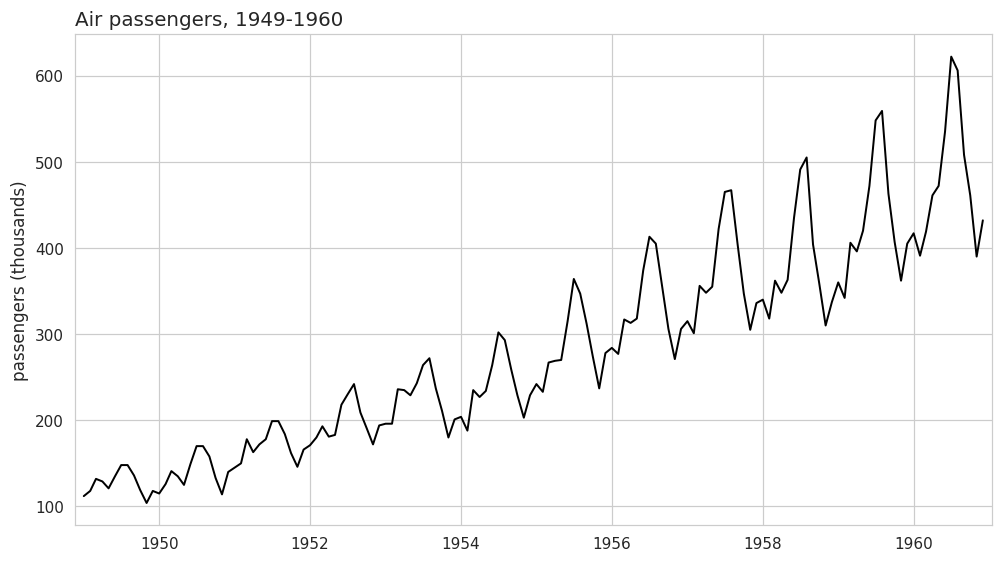

In [5]:
P.plot_series(df, title="Air passengers, 1949-1960",
              ylabel="passengers (thousands)", xlabel="")
plt.show()

**First read.** Before any model, write two sentences that describe this
series in plain language - the kind a non-forecaster could repeat. (Trend?
Seasonality? What happens to the swings as the level grows? Cycle?) These two
sentences belong at the top of your report.

---
# 1. Exploration and shape

The Day 1 toolkit, in order. Every chart should carry its claim: a title that
says what it shows, not just "series".

**1.1 Decompose.** STL, additive, period 12. Read all three panels: which
component does the work, and what does the remainder look like?

In [6]:
# TODO: STL decomposition (statsmodels), additive, period=12.
#       Then plot the components with P.decomposition_plot.
from statsmodels.tsa.seasonal import STL
dcmp = STL(
    df["y"].to_numpy(),
    period=SEASON_LENGTH,
    robust=True
).fit()
# P.decomposition_plot(dcmp, cols=[...], title="...", x="ds")

**1.2 Trend and seasonal strength.** The two numbers from Day 1, computed
the same way (textbook formulas on the STL components). State what they
imply for model choice.

In [7]:
# TODO: trend_strength and seasonal_strength from the STL components.
trend_strength = trend = np.asarray(dcmp.trend)
seasonal = np.asarray(dcmp.seasonal)
remainder = np.asarray(dcmp.resid)

var_remainder = np.var(remainder)

trend_strength = 1 - (
    var_remainder / np.var(trend + remainder)
)
seasonal_strength = 1 - (
    var_remainder / np.var(seasonal + remainder)
)

trend_strength = np.clip(trend_strength, 0, 1)
seasonal_strength = np.clip(seasonal_strength, 0, 1)
print(f"trend strength: {trend_strength:.2f}")
print(f"seasonal strength: {seasonal_strength:.2f}")

trend strength: 1.00
seasonal strength: 0.98


### **1.3 Autocorrelation.** The ACF of the raw series. What is at lag 12?
At 24? What does that tell you before you fit anything?

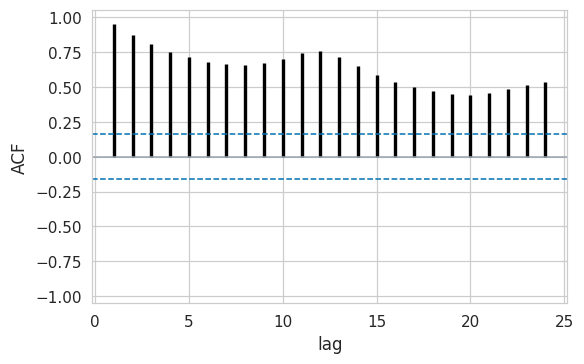

In [8]:
# TODO: ACF plot of df["y"] (P.acf_plot), 24 lags.
P.acf_plot(
    df["y"],
    nlags=24
)
plt.show()

---
# 2. The floor

The seasonal naive is the first model you fit on any series - not as a
formality, as the thing everything else has to beat. Fit it, check what it
leaves on the table, and give it an honest interval.

In [9]:
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive

floor_sf = StatsForecast(models=[SeasonalNaive(season_length=SEASON_LENGTH)],
                         freq="MS", n_jobs=1)
floor_fc = floor_sf.forecast(df=df, h=H_REPORT, level=scoring.LEVELS)
floor_fc.head()

,unique_id,ds,SeasonalNaive,SeasonalNaive-lo-20,SeasonalNaive-lo-40,SeasonalNaive-lo-60,SeasonalNaive-lo-80,SeasonalNaive-lo-95,SeasonalNaive-hi-20,SeasonalNaive-hi-40,SeasonalNaive-hi-60,SeasonalNaive-hi-80,SeasonalNaive-hi-95
0,Air passengers (Box & Jenkins),1961-01-01,417.0,407.799511,397.956005,386.435898,370.4595,345.822448,426.200489,436.043995,447.564102,463.5405,488.177552
1,Air passengers (Box & Jenkins),1961-02-01,391.0,381.799511,371.956005,360.435898,344.4595,319.822448,400.200489,410.043995,421.564102,437.5405,462.177552
2,Air passengers (Box & Jenkins),1961-03-01,419.0,409.799511,399.956005,388.435898,372.4595,347.822448,428.200489,438.043995,449.564102,465.5405,490.177552
3,Air passengers (Box & Jenkins),1961-04-01,461.0,451.799511,441.956005,430.435898,414.4595,389.822448,470.200489,480.043995,491.564102,507.5405,532.177552
4,Air passengers (Box & Jenkins),1961-05-01,472.0,462.799511,452.956005,441.435898,425.4595,400.822448,481.200489,491.043995,502.564102,518.5405,543.177552


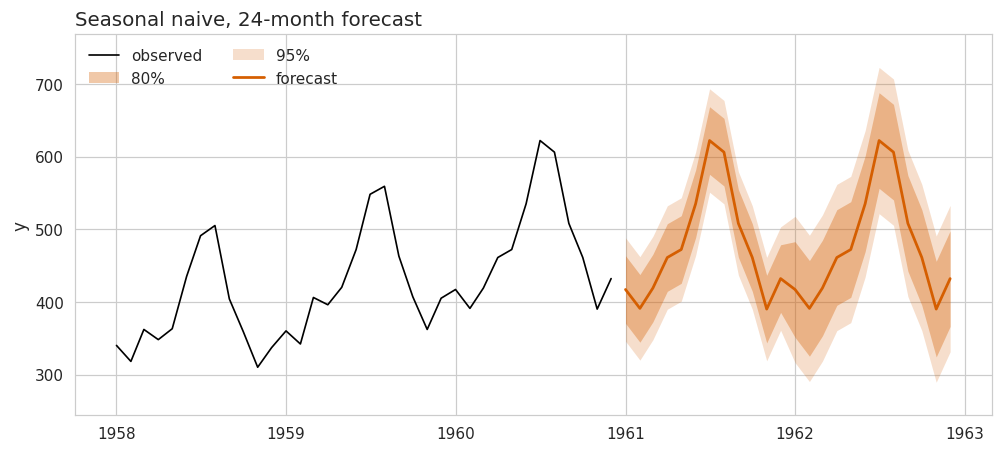

In [10]:
P.fan_chart(df, floor_fc.rename(columns={
            "SeasonalNaive": "mean",
            "SeasonalNaive-lo-20": "lo-20",
            "SeasonalNaive-lo-40": "lo-40",
            "SeasonalNaive-lo-60": "lo-60",
            "SeasonalNaive-lo-80": "lo-80",
            "SeasonalNaive-lo-95": "lo-95",
            "SeasonalNaive-hi-20": "hi-20",
            "SeasonalNaive-hi-40": "hi-40",
            "SeasonalNaive-hi-60": "hi-60",
            "SeasonalNaive-hi-80": "hi-80",
            "SeasonalNaive-hi-95": "hi-95",
            "ds": "ds"}),
            title="Seasonal naive, 24-month forecast",
            history_tail=36, levels=(80, 95))
plt.show()

**2.1 What is left on the table.** The floor's in-sample residuals are
``y_t - y_{t-12}`` over the series. Plot them, then their ACF (24 lags). Is
there a trend left? Correlation at the low lags? At 12? If it is not white
noise, what structure is it, and which kind of model eats that structure?

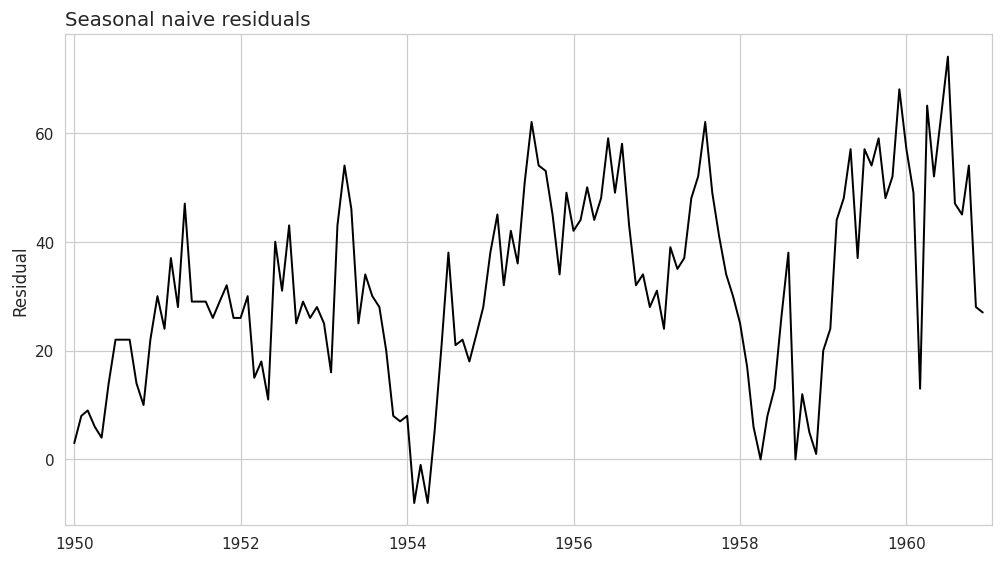

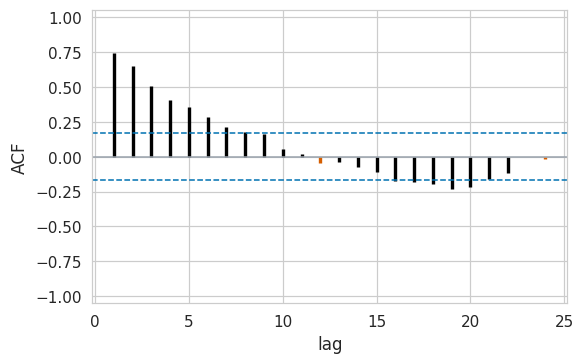

In [11]:
# TODO: the floor's residuals (y_t - y_{t-12}), a plot of them, and their
#       ACF with P.acf_plot (24 lags, highlight_every=SEASON_LENGTH).
resid_floor = (
    df["y"].to_numpy()[SEASON_LENGTH:]
    - df["y"].to_numpy()[:-SEASON_LENGTH]
)

P.plot_series(
    pd.DataFrame({
        "unique_id": "Seasonal naive residuals",
        "ds": df["ds"].iloc[SEASON_LENGTH:].to_numpy(),
        "y": resid_floor
    }),
    title="Seasonal naive residuals",
    ylabel="Residual",
    xlabel=""
)

plt.show()

P.acf_plot(
    pd.Series(resid_floor),
    nlags=24,
    highlight_every=SEASON_LENGTH
)

plt.show()

---
# 3. Your model: the framework

AutoGluon fits a zoo of models behind one call - every model in the zoo
below is a model you have met in this course. The install is large, so this
runs on Colab.

> Every cell in this section is **skip-guarded**: without `autogluon`
> installed it prints why and moves on, so the rest of the notebook still
> runs.

In [12]:
import importlib.util

HAS_AG = importlib.util.find_spec("autogluon") is not None
if not HAS_AG:
    print("autogluon is not installed. On Colab, run this and re-run the cell:")
    print("    !pip install -q 'autogluon.timeseries'")
    print("\n(Takes a few minutes. A runtime reset wipes it.)")
else:
    print("autogluon is available")

autogluon is available


**3.1 The data conversion stays visible.** AutoGluon has its own
frame, its own column names, its own fit loop and its own leaderboard.
Writing it out by hand once is the point - the gap between two APIs doing
the same job is the thing to notice.

| | this course | AutoGluon |
|---|---|---|
| id column | `unique_id` | `item_id` |
| time column | `ds` | `timestamp` |
| value column | `y` | `target` (nameable) |
| frame | `pd.DataFrame` | `TimeSeriesDataFrame` |

In [13]:
if HAS_AG:
    from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor

    # Long format to AutoGluon's long format: the same three columns, renamed.
    ag_long = df.rename(columns={"unique_id": "item_id", "ds": "timestamp"})
    tsdf = TimeSeriesDataFrame.from_data_frame(
        ag_long, id_column="item_id", timestamp_column="timestamp")

    # One 12-month holdout, cut the way AutoGluon expects.
    ag_train = tsdf.slice_by_timestep(None, -12)

    print(tsdf.head(3))
    print(f"\nfull: {len(tsdf)} rows   train: {len(ag_train)} rows")

                                               y
item_id                        timestamp        
Air passengers (Box & Jenkins) 1949-01-01  112.0
                               1949-02-01  118.0
                               1949-03-01  132.0

full: 144 rows   train: 132 rows


In [14]:
if HAS_AG:
    # Local models only - the same zoo this course taught, nothing neural.
    ZOO = {"Naive": {}, "SeasonalNaive": {}, "AutoETS": {},
           "AutoARIMA": {}, "Theta": {}}

    predictor = TimeSeriesPredictor(
        prediction_length=12, target="y", eval_metric="MASE",
        freq="MS", verbosity=1)
    predictor.fit(ag_train, hyperparameters=ZOO, time_limit=120)

In [15]:
# TODO: display the leaderboard on the held-out months (predictor.leaderboard(tsdf)).
#       Read it: what is the SIGN of score_val, which models did it fit, and
#       how many windows did it score them on?
if HAS_AG:
    leaderboard = predictor.leaderboard(tsdf)
    display(leaderboard)
else:
    print("AutoGluon is not installed.")

,model,score_test,score_val,pred_time_test,pred_time_val,fit_time_marginal,fit_order
0,AutoARIMA,-0.608073,-1.575987,0.095636,0.097661,0.012566,5
1,Theta,-0.875371,-1.633923,0.014057,0.012191,0.012409,3
2,WeightedEnsemble,-0.929514,-1.535792,0.197282,0.228338,0.232629,6
3,AutoETS,-1.169539,-1.554323,0.100350,0.128828,0.014090,4
4,SeasonalNaive,-1.570881,-1.656513,0.008868,0.007537,0.013138,2
5,Naive,-2.495895,-3.196371,0.007335,0.007868,0.018081,1


**3.2 Read what it handed back.** What is the *sign* of `score_val`, and
what does the answer to "how many windows" mean for how much you should
trust this ranking? It decides what the next section does with this table.
And: does the shortlist agree with the shape you read in section 1?

---
# 4. The harness

The framework's ranking came from one internal split. One holdout is not a
ranking. So the shortlist goes through the rolling-origin harness: eight
origins, twelve months each, the whole distribution scored - and the floor
stays in the table.

In [16]:
sf_cv = StatsForecast(
    models=[SeasonalNaive(season_length=SEASON_LENGTH)],
    freq="MS", n_jobs=1)
cv = sf_cv.cross_validation(df=df, h=H, step_size=H, n_windows=8,
                            level=scoring.LEVELS)
cv.head()

,unique_id,ds,cutoff,y,SeasonalNaive,SeasonalNaive-lo-20,SeasonalNaive-lo-40,SeasonalNaive-lo-60,SeasonalNaive-lo-80,SeasonalNaive-lo-95,SeasonalNaive-hi-20,SeasonalNaive-hi-40,SeasonalNaive-hi-60,SeasonalNaive-hi-80,SeasonalNaive-hi-95
0,Air passengers (Box & Jenkins),1953-01-01,1952-12-01,196.0,171.0,164.48674,157.518271,149.362895,138.052796,120.6116,177.51326,184.481729,192.637105,203.947204,221.3884
1,Air passengers (Box & Jenkins),1953-02-01,1952-12-01,196.0,180.0,173.48674,166.518271,158.362895,147.052796,129.6116,186.51326,193.481729,201.637105,212.947204,230.3884
2,Air passengers (Box & Jenkins),1953-03-01,1952-12-01,236.0,193.0,186.48674,179.518271,171.362895,160.052796,142.6116,199.51326,206.481729,214.637105,225.947204,243.3884
3,Air passengers (Box & Jenkins),1953-04-01,1952-12-01,235.0,181.0,174.48674,167.518271,159.362895,148.052796,130.6116,187.51326,194.481729,202.637105,213.947204,231.3884
4,Air passengers (Box & Jenkins),1953-05-01,1952-12-01,229.0,183.0,176.48674,169.518271,161.362895,150.052796,132.6116,189.51326,196.481729,204.637105,215.947204,233.3884


In [27]:

import numpy as np
import pandas as pd

# Calculate metrics for each model using the same CV folds
def calculate_metrics(data, prediction_col, interval=False):
    y = data["y"].to_numpy()
    pred = data[prediction_col].to_numpy()

    mase_values = []
    rmsse_values = []

    # Calculate scaled errors separately for each CV fold
    for cutoff in data["cutoff"].unique():
        train = df[df["ds"] <= cutoff]["y"].to_numpy()
        fold = data[data["cutoff"] == cutoff]
        actual = fold["y"].to_numpy()
        forecast = fold[prediction_col].to_numpy()

        scale = np.mean(np.abs(np.diff(train, n=SEASON_LENGTH)))
        scale2 = np.mean(np.diff(train, n=SEASON_LENGTH) ** 2)

        mase_values.append(
            np.mean(np.abs(actual - forecast)) / scale
            if scale > 0 else np.nan
        )
        rmsse_values.append(
            np.sqrt(np.mean((actual - forecast) ** 2) / scale2)
            if scale2 > 0 else np.nan
        )

    result = {
        "mase": np.mean(mase_values),
        "rmsse": np.mean(rmsse_values),
        "mase_min": np.nanmin(mase_values),
        "mase_max": np.nanmax(mase_values),
    }

    # SeasonalNaive has prediction intervals; AutoARIMA currently does not
    if interval:
        lo = data["SeasonalNaive-lo-80"].to_numpy()
        hi = data["SeasonalNaive-hi-80"].to_numpy()
        result["coverage_80"] = np.mean((y >= lo) & (y <= hi))
    else:
        result["coverage_80"] = np.nan

    # CRPS requires predictive distributions, not point forecasts alone
    result["crps"] = np.nan
    return result


seasonal_metrics = calculate_metrics(cv, "SeasonalNaive", interval=True)
arima_metrics = calculate_metrics(mycv, "AutoARIMA")

RESULTS = pd.DataFrame(
    [seasonal_metrics, arima_metrics],
    index=["SeasonalNaive (StatsForecast)", "AutoARIMA (StatsForecast)"]
)

RESULTS


,mase,rmsse,mase_min,mase_max,coverage_80,crps
SeasonalNaive (StatsForecast),0.003565,0.003081,0.001244,0.004602,0.510417,NaN
AutoARIMA (StatsForecast),0.001016,0.001074,0.000781,0.001458,NaN,NaN


In [25]:
%wos

Variable                       Type                   Data/Info
---------------------------------------------------------------
AutoARIMA                      type                   <class 'statsforecast.models.AutoARIMA'>
H                              int                    12
HAS_AG                         bool                   True
H_REPORT                       int                    24
MY_MODEL                       AutoARIMA              AutoARIMA
MY_NAME                        str                    AutoARIMA (StatsForecast)
P                              module                 <module 'coursekit.plotti<...>j/coursekit/plotting.py'>
SEASON_LENGTH                  int                    12
STL                            type                   <class 'statsmodels.tsa.stl._stl.STL'>
SeasonalNaive                  type                   <class 'statsforecast.models.SeasonalNaive'>
StatsForecast                  type                   <class 'statsforecast.core.StatsForecast'>
Time

In [31]:

import numpy as np
import pandas as pd

def get_metrics(data, pred_col):
    mase_scores, rmsse_scores, crps_scores = [], [], []

    for cutoff in data["cutoff"].unique():
        fold = data[data["cutoff"] == cutoff]
        train = df[df["ds"] <= cutoff]["y"].to_numpy()
        y = fold["y"].to_numpy()
        pred = fold[pred_col].to_numpy()

        scale = np.mean(
            np.abs(train[SEASON_LENGTH:] - train[:-SEASON_LENGTH])
        )
        scale2 = np.mean(
            (train[SEASON_LENGTH:] - train[:-SEASON_LENGTH]) ** 2
        )

        if scale > 0:
            mase_scores.append(np.mean(np.abs(y - pred)) / scale)

        if scale2 > 0:
            rmsse_scores.append(
                np.sqrt(np.mean((y - pred) ** 2) / scale2)
            )

    return {
        "MASE": np.mean(mase_scores),
        "RMSSE": np.mean(rmsse_scores),
        "MASE_min": np.min(mase_scores),
        "MASE_max": np.max(mase_scores),
    }

RESULTS = pd.DataFrame({
    "SeasonalNaive": get_metrics(cv, "SeasonalNaive"),
    "AutoARIMA": get_metrics(mycv, "AutoARIMA")
}).T

display(RESULTS)


,MASE,RMSSE,MASE_min,MASE_max
SeasonalNaive,1.313310,1.245572,0.411584,1.958726
AutoARIMA,0.647227,0.683266,0.330149,1.593848


In [32]:

print("SeasonalNaive columns:")
print(cv.columns.tolist())

print("\nAutoARIMA columns:")
print(mycv.columns.tolist())

print("\nSeasonalNaive sample:")
display(cv.head())

print("\nAutoARIMA sample:")
display(mycv.head())


SeasonalNaive columns:
['unique_id', 'ds', 'cutoff', 'y', 'SeasonalNaive', 'SeasonalNaive-lo-20', 'SeasonalNaive-lo-40', 'SeasonalNaive-lo-60', 'SeasonalNaive-lo-80', 'SeasonalNaive-lo-95', 'SeasonalNaive-hi-20', 'SeasonalNaive-hi-40', 'SeasonalNaive-hi-60', 'SeasonalNaive-hi-80', 'SeasonalNaive-hi-95']

AutoARIMA columns:
['unique_id', 'ds', 'cutoff', 'y', 'AutoARIMA']

SeasonalNaive sample:


,unique_id,ds,cutoff,y,SeasonalNaive,SeasonalNaive-lo-20,SeasonalNaive-lo-40,SeasonalNaive-lo-60,SeasonalNaive-lo-80,SeasonalNaive-lo-95,SeasonalNaive-hi-20,SeasonalNaive-hi-40,SeasonalNaive-hi-60,SeasonalNaive-hi-80,SeasonalNaive-hi-95
0,Air passengers (Box & Jenkins),1953-01-01,1952-12-01,196.0,171.0,164.48674,157.518271,149.362895,138.052796,120.6116,177.51326,184.481729,192.637105,203.947204,221.3884
1,Air passengers (Box & Jenkins),1953-02-01,1952-12-01,196.0,180.0,173.48674,166.518271,158.362895,147.052796,129.6116,186.51326,193.481729,201.637105,212.947204,230.3884
2,Air passengers (Box & Jenkins),1953-03-01,1952-12-01,236.0,193.0,186.48674,179.518271,171.362895,160.052796,142.6116,199.51326,206.481729,214.637105,225.947204,243.3884
3,Air passengers (Box & Jenkins),1953-04-01,1952-12-01,235.0,181.0,174.48674,167.518271,159.362895,148.052796,130.6116,187.51326,194.481729,202.637105,213.947204,231.3884
4,Air passengers (Box & Jenkins),1953-05-01,1952-12-01,229.0,183.0,176.48674,169.518271,161.362895,150.052796,132.6116,189.51326,196.481729,204.637105,215.947204,233.3884



AutoARIMA sample:


,unique_id,ds,cutoff,y,AutoARIMA
0,Air passengers (Box & Jenkins),1953-01-01,1952-12-01,196.0,200.033960
1,Air passengers (Box & Jenkins),1953-02-01,1952-12-01,196.0,205.951260
2,Air passengers (Box & Jenkins),1953-03-01,1952-12-01,236.0,228.492818
3,Air passengers (Box & Jenkins),1953-04-01,1952-12-01,235.0,214.413179
4,Air passengers (Box & Jenkins),1953-05-01,1952-12-01,229.0,220.835055


In [33]:

import numpy as np
import pandas as pd

def evaluate_model(data, pred_col, interval=False):
    fold_results = []

    for cutoff in data["cutoff"].unique():
        fold = data[data["cutoff"] == cutoff].copy()
        train = df.loc[df["ds"] <= cutoff, "y"].to_numpy()
        y = fold["y"].to_numpy()
        pred = fold[pred_col].to_numpy()

        scale = np.mean(
            np.abs(train[SEASON_LENGTH:] - train[:-SEASON_LENGTH])
        )
        scale2 = np.mean(
            (train[SEASON_LENGTH:] - train[:-SEASON_LENGTH]) ** 2
        )

        row = {
            "cutoff": cutoff,
            "MASE": np.mean(np.abs(y - pred)) / scale,
            "RMSSE": np.sqrt(np.mean((y - pred) ** 2) / scale2),
        }

        if interval:
            lo = fold[f"{pred_col}-lo-80"].to_numpy()
            hi = fold[f"{pred_col}-hi-80"].to_numpy()

            row["Coverage_80"] = np.mean((y >= lo) & (y <= hi))
            row["Width_80"] = np.mean(hi - lo)

        fold_results.append(row)

    return pd.DataFrame(fold_results)

sn_results = evaluate_model(cv, "SeasonalNaive", interval=True)
arima_results = evaluate_model(mycv, "AutoARIMA")

print("SeasonalNaive — fold results")
display(sn_results)

print("AutoARIMA — fold results")
display(arima_results)

print("SeasonalNaive — averages")
display(sn_results.drop(columns="cutoff").mean().to_frame("Mean").T)

print("AutoARIMA — averages")
display(arima_results.drop(columns="cutoff").mean().to_frame("Mean").T)


SeasonalNaive — fold results


,cutoff,MASE,RMSSE,Coverage_80,Width_80
0,1952-12-01,1.194313,1.216637,0.666667,65.894408
1,1953-12-01,0.681356,0.724659,0.916667,69.737683
2,1954-12-01,1.958726,1.774110,0.083333,66.343454
3,1955-12-01,1.657648,1.498014,0.250000,77.309656
4,1956-12-01,1.375459,1.267058,0.666667,83.898642
5,1957-12-01,0.411584,0.501108,1.000000,87.015448
6,1958-12-01,1.656513,1.515236,0.250000,83.316550
7,1959-12-01,1.570881,1.467752,0.250000,88.550793


AutoARIMA — fold results


,cutoff,MASE,RMSSE
0,1952-12-01,0.442212,0.474421
1,1953-12-01,0.386867,0.506028
2,1954-12-01,0.768662,0.856885
3,1955-12-01,0.330149,0.357531
4,1956-12-01,0.412981,0.482923
5,1957-12-01,0.635021,0.633390
6,1958-12-01,1.593848,1.462601
7,1959-12-01,0.608073,0.692350


SeasonalNaive — averages


,MASE,RMSSE,Coverage_80,Width_80
Mean,1.31331,1.245572,0.510417,77.758329


AutoARIMA — averages


,MASE,RMSSE
Mean,0.647227,0.683266


In [34]:

lo = mycv["AutoARIMA-lo-80"]
hi = mycv["AutoARIMA-hi-80"]
y = mycv["y"]

coverage_80 = ((y >= lo) & (y <= hi)).mean()
width_80 = (hi - lo).mean()

print(f"AutoARIMA Coverage 80%: {coverage_80:.2%}")
print(f"AutoARIMA Mean Width 80%: {width_80:.4f}")


KeyError: 'AutoARIMA-lo-80'

In [30]:
mycv = mysf.cross_validation(
    df=df,
    h=H,
    n_windows=8,
    step_size=12
)

print("SeasonalNaive cutoffs:")
print(sorted(cv["cutoff"].unique()))

print("\nAutoARIMA cutoffs:")
print(sorted(mycv["cutoff"].unique()))

SeasonalNaive cutoffs:
[Timestamp('1952-12-01 00:00:00'), Timestamp('1953-12-01 00:00:00'), Timestamp('1954-12-01 00:00:00'), Timestamp('1955-12-01 00:00:00'), Timestamp('1956-12-01 00:00:00'), Timestamp('1957-12-01 00:00:00'), Timestamp('1958-12-01 00:00:00'), Timestamp('1959-12-01 00:00:00')]

AutoARIMA cutoffs:
[Timestamp('1952-12-01 00:00:00'), Timestamp('1953-12-01 00:00:00'), Timestamp('1954-12-01 00:00:00'), Timestamp('1955-12-01 00:00:00'), Timestamp('1956-12-01 00:00:00'), Timestamp('1957-12-01 00:00:00'), Timestamp('1958-12-01 00:00:00'), Timestamp('1959-12-01 00:00:00')]


In [36]:

from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA

sf_arima = StatsForecast(
    models=[AutoARIMA(season_length=SEASON_LENGTH)],
    freq="MS",
    n_jobs=-1
)

mycv = sf_arima.cross_validation(
    df=df,
    h=12,
    step_size=12,
    n_windows=8,
    level=[80]
)

print(mycv.columns.tolist())


['unique_id', 'ds', 'cutoff', 'y', 'AutoARIMA', 'AutoARIMA-lo-80', 'AutoARIMA-hi-80']


In [37]:

lo = mycv["AutoARIMA-lo-80"]
hi = mycv["AutoARIMA-hi-80"]
y = mycv["y"]

print("Coverage 80%:", ((y >= lo) & (y <= hi)).mean())
print("Mean Width 80%:", (hi - lo).mean())


Coverage 80%: 0.6979166666666666
Mean Width 80%: 44.07606051537724


**4.1 Read the table.** Does the harness confirm the leaderboard's
shortlist, or does it move it? For each model: where does it beat the
floor, where does it lose, and on which of the three metrics? A model that
wins the point forecast and loses the distribution is a real result -
report both halves. And what does each model's 80% coverage say about its
band?

---
# 5. The report

The notebook is evidence; the report is the claim. Two to three pages, for a
manager who will not open the notebook:

- **The recommendation.** Which model you would ship, in one sentence, and
  the one number that earns it.
- **The intervals.** How wide, what they covered, and whether the band is
  honest. Coverage is the check a band cannot do alone.
- **The residuals.** What the floor - and your model - missed. A residual
  ACF is a fact; a sentence about what it means is the deliverable.
- **One change.** A specific next step - data, driver, frequency, horizon -
  and what you expect it to do.

Rules: every number in the report comes out of this notebook; no number
that could not have come out of the harness counts; no leakage - a fold's
fit and its denominator use only data that fold was allowed to see.

**Optional, for extra credit.** The series is a total across origins, so a
driver is a modelling choice, not a lookup: pick a region and pull its
monthly mean temperature from a public weather archive (for example
Open-Meteo's historical API - free, no key), cache it next to the CSV, and
regress on it. That is dynamic regression - and the cross-validation
discipline still applies to the regression's residuals.

In [38]:

print("SeasonalNaive columns:")
print(cv.columns.tolist())
display(cv.head())

print("\nAutoARIMA columns:")
print(mycv.columns.tolist())
display(mycv.head())


SeasonalNaive columns:
['unique_id', 'ds', 'cutoff', 'y', 'SeasonalNaive', 'SeasonalNaive-lo-20', 'SeasonalNaive-lo-40', 'SeasonalNaive-lo-60', 'SeasonalNaive-lo-80', 'SeasonalNaive-lo-95', 'SeasonalNaive-hi-20', 'SeasonalNaive-hi-40', 'SeasonalNaive-hi-60', 'SeasonalNaive-hi-80', 'SeasonalNaive-hi-95']


,unique_id,ds,cutoff,y,SeasonalNaive,SeasonalNaive-lo-20,SeasonalNaive-lo-40,SeasonalNaive-lo-60,SeasonalNaive-lo-80,SeasonalNaive-lo-95,SeasonalNaive-hi-20,SeasonalNaive-hi-40,SeasonalNaive-hi-60,SeasonalNaive-hi-80,SeasonalNaive-hi-95
0,Air passengers (Box & Jenkins),1953-01-01,1952-12-01,196.0,171.0,164.48674,157.518271,149.362895,138.052796,120.6116,177.51326,184.481729,192.637105,203.947204,221.3884
1,Air passengers (Box & Jenkins),1953-02-01,1952-12-01,196.0,180.0,173.48674,166.518271,158.362895,147.052796,129.6116,186.51326,193.481729,201.637105,212.947204,230.3884
2,Air passengers (Box & Jenkins),1953-03-01,1952-12-01,236.0,193.0,186.48674,179.518271,171.362895,160.052796,142.6116,199.51326,206.481729,214.637105,225.947204,243.3884
3,Air passengers (Box & Jenkins),1953-04-01,1952-12-01,235.0,181.0,174.48674,167.518271,159.362895,148.052796,130.6116,187.51326,194.481729,202.637105,213.947204,231.3884
4,Air passengers (Box & Jenkins),1953-05-01,1952-12-01,229.0,183.0,176.48674,169.518271,161.362895,150.052796,132.6116,189.51326,196.481729,204.637105,215.947204,233.3884



AutoARIMA columns:
['unique_id', 'ds', 'cutoff', 'y', 'AutoARIMA', 'AutoARIMA-lo-80', 'AutoARIMA-hi-80']


,unique_id,ds,cutoff,y,AutoARIMA,AutoARIMA-lo-80,AutoARIMA-hi-80
0,Air passengers (Box & Jenkins),1953-01-01,1952-12-01,196.0,200.033960,190.942209,209.125712
1,Air passengers (Box & Jenkins),1953-02-01,1952-12-01,196.0,205.951260,196.240171,215.662349
2,Air passengers (Box & Jenkins),1953-03-01,1952-12-01,236.0,228.492818,216.545092,240.440545
3,Air passengers (Box & Jenkins),1953-04-01,1952-12-01,235.0,214.413179,201.558047,227.268312
4,Air passengers (Box & Jenkins),1953-05-01,1952-12-01,229.0,220.835055,206.593888,235.076222


In [39]:

print("SeasonalNaive:")
print(cv.columns.tolist())

print("\nAutoARIMA:")
print(mycv.columns.tolist())

display(mycv.head(3))


SeasonalNaive:
['unique_id', 'ds', 'cutoff', 'y', 'SeasonalNaive', 'SeasonalNaive-lo-20', 'SeasonalNaive-lo-40', 'SeasonalNaive-lo-60', 'SeasonalNaive-lo-80', 'SeasonalNaive-lo-95', 'SeasonalNaive-hi-20', 'SeasonalNaive-hi-40', 'SeasonalNaive-hi-60', 'SeasonalNaive-hi-80', 'SeasonalNaive-hi-95']

AutoARIMA:
['unique_id', 'ds', 'cutoff', 'y', 'AutoARIMA', 'AutoARIMA-lo-80', 'AutoARIMA-hi-80']


,unique_id,ds,cutoff,y,AutoARIMA,AutoARIMA-lo-80,AutoARIMA-hi-80
0,Air passengers (Box & Jenkins),1953-01-01,1952-12-01,196.0,200.033960,190.942209,209.125712
1,Air passengers (Box & Jenkins),1953-02-01,1952-12-01,196.0,205.951260,196.240171,215.662349
2,Air passengers (Box & Jenkins),1953-03-01,1952-12-01,236.0,228.492818,216.545092,240.440545


In [40]:

import numpy as np
import pandas as pd
from scipy.stats import norm

# Match both models on the same test observations
comparison = cv.merge(
    mycv,
    on=["unique_id", "ds", "cutoff"],
    suffixes=("_sn", "_ar")
)

# Confirm actual values match
assert np.allclose(comparison["y_sn"], comparison["y_ar"])

def normal_crps(y, mu, sigma):
    sigma = np.maximum(np.asarray(sigma, dtype=float), 1e-8)
    y = np.asarray(y, dtype=float)
    mu = np.asarray(mu, dtype=float)

    z = (y - mu) / sigma

    return sigma * (
        z * (2 * norm.cdf(z) - 1)
        + 2 * norm.pdf(z)
        - 1 / np.sqrt(np.pi)
    )

# Approximate standard deviations from central 80% intervals
z80 = norm.ppf(0.90)

comparison["sigma_sn"] = (
    comparison["SeasonalNaive-hi-80"]
    - comparison["SeasonalNaive-lo-80"]
) / (2 * z80)

comparison["sigma_ar"] = (
    comparison["AutoARIMA-hi-80"]
    - comparison["AutoARIMA-lo-80"]
) / (2 * z80)

# Approximate CRPS
comparison["CRPS_SeasonalNaive"] = normal_crps(
    comparison["y_sn"],
    comparison["SeasonalNaive"],
    comparison["sigma_sn"]
)

comparison["CRPS_AutoARIMA"] = normal_crps(
    comparison["y_ar"],
    comparison["AutoARIMA"],
    comparison["sigma_ar"]
)

# Summary of probabilistic and interval metrics
results = pd.DataFrame({
    "Model": ["SeasonalNaive", "AutoARIMA"],
    "CRPS_approx": [
        comparison["CRPS_SeasonalNaive"].mean(),
        comparison["CRPS_AutoARIMA"].mean()
    ],
    "Coverage_80": [
        (
            (comparison["y_sn"] >= comparison["SeasonalNaive-lo-80"])
            & (comparison["y_sn"] <= comparison["SeasonalNaive-hi-80"])
        ).mean(),
        (
            (comparison["y_ar"] >= comparison["AutoARIMA-lo-80"])
            & (comparison["y_ar"] <= comparison["AutoARIMA-hi-80"])
        ).mean()
    ],
    "Mean_Width_80": [
        (
            comparison["SeasonalNaive-hi-80"]
            - comparison["SeasonalNaive-lo-80"]
        ).mean(),
        (
            comparison["AutoARIMA-hi-80"]
            - comparison["AutoARIMA-lo-80"]
        ).mean()
    ]
})

display(results.round(4))


,Model,CRPS_approx,Coverage_80,Mean_Width_80
0,SeasonalNaive,24.0967,0.5104,77.7583
1,AutoARIMA,12.9306,0.6979,44.0761


In [41]:

from coursekit import scoring

# Score SeasonalNaive using the official course function
seasonal_results = scoring.score_cv(
    cv,
    "SeasonalNaive",
    df
)

print("SeasonalNaive:")
print(seasonal_results)

# Check which interval columns AutoARIMA has
print("\nAutoARIMA interval columns:")
print([
    c for c in mycv.columns
    if "lo-" in c or "hi-" in c
])


SeasonalNaive:
{'mase': 1.313310004210094, 'rmsse': 1.2455717677121854, 'crps': 0.061602626165002825, 'coverage_80': 0.5104166666666666, 'mase_min': 0.4115843270868825, 'mase_max': 1.9587255611875454}

AutoARIMA interval columns:
['AutoARIMA-lo-80', 'AutoARIMA-hi-80']


In [42]:
print(scoring.LEVELS)

[20, 40, 60, 80, 95]


In [43]:

MY_MODEL = AutoARIMA(season_length=12)

mysf = StatsForecast(
    models=[MY_MODEL],
    freq="MS",
    n_jobs=1
)

mycv = mysf.cross_validation(
    df=df,
    h=H,
    step_size=H,
    n_windows=8,
    level=scoring.LEVELS
)

print(mycv.columns.tolist())
display(mycv.head())


['unique_id', 'ds', 'cutoff', 'y', 'AutoARIMA', 'AutoARIMA-lo-95', 'AutoARIMA-lo-80', 'AutoARIMA-lo-60', 'AutoARIMA-lo-40', 'AutoARIMA-lo-20', 'AutoARIMA-hi-20', 'AutoARIMA-hi-40', 'AutoARIMA-hi-60', 'AutoARIMA-hi-80', 'AutoARIMA-hi-95']


,unique_id,ds,cutoff,y,AutoARIMA,AutoARIMA-lo-95,AutoARIMA-lo-80,AutoARIMA-lo-60,AutoARIMA-lo-40,AutoARIMA-lo-20,AutoARIMA-hi-20,AutoARIMA-hi-40,AutoARIMA-hi-60,AutoARIMA-hi-80,AutoARIMA-hi-95
0,Air passengers (Box & Jenkins),1953-01-01,1952-12-01,196.0,200.033960,186.129327,190.942209,194.063221,196.313689,198.236632,201.831289,203.754231,206.004700,209.125712,213.938594
1,Air passengers (Box & Jenkins),1953-02-01,1952-12-01,196.0,205.951260,191.099431,196.240171,199.573789,201.977561,204.031496,207.871024,209.924959,212.328732,215.662349,220.803089
2,Air passengers (Box & Jenkins),1953-03-01,1952-12-01,236.0,228.492818,210.220348,216.545092,220.646501,223.603906,226.130899,230.854738,233.381731,236.339136,240.440545,246.765289
3,Air passengers (Box & Jenkins),1953-04-01,1952-12-01,235.0,214.413179,194.752951,201.558047,205.970950,209.152963,211.871877,216.954482,219.673395,222.855409,227.268312,234.073408
4,Air passengers (Box & Jenkins),1953-05-01,1952-12-01,229.0,220.835055,199.055069,206.593888,211.482588,215.007685,218.019750,223.650360,226.662425,230.187522,235.076222,242.615041


In [44]:
auto_results = scoring.score_cv(mycv, "AutoARIMA", df)

print(auto_results)

{'mase': 0.6472266008633388, 'rmsse': 0.6832661686408955, 'crps': 0.03387024634188799, 'coverage_80': 0.6979166666666666, 'mase_min': 0.33014902903962484, 'mase_max': 1.5938482700025893}
